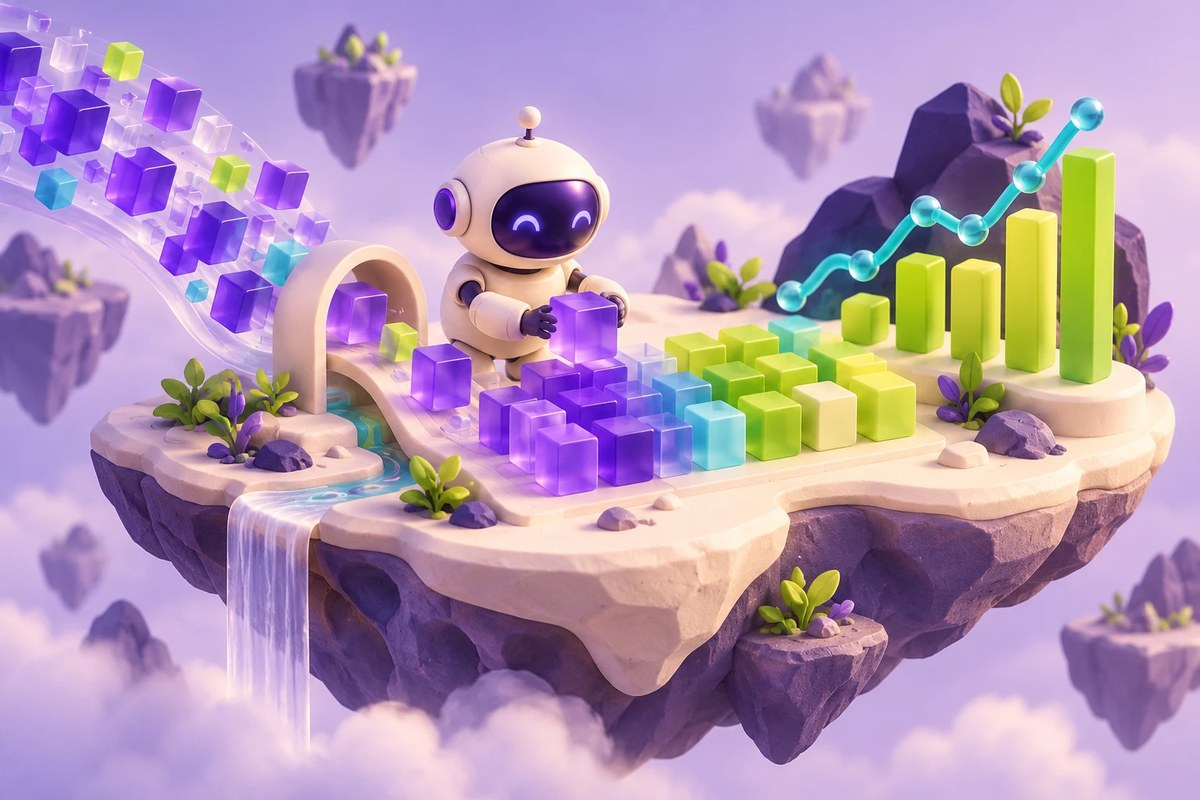

AI PATH · Python для машинного обучения · Урок 023

# Графики функций и исследование данных

От кривой экспоненты до распределений, корреляций и временных рядов.

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-023-goal"></a>
## Что вы разберёте

Выбирать график под вопрос и объяснять, какие данные и преобразования стоят за изображением.

### Перед началом

- Массивы NumPy и индексация
- Таблицы Pandas и базовая статистика

### Что понадобится

- NumPy, Matplotlib, Pandas, Seaborn, SciPy и scikit-learn
- Файл /content/datatraining.txt с date, Temperature, Humidity, Light, CO2, HumidityRatio и Occupancy
- Iris загружается из sklearn.datasets; графики рассчитаны на IPython

## Навигация по уроку

- [Цель и подготовка](#ai-023-goal)
- [Карта урока](#ai-023-map)
- [Функция и её оси](#ai-023-section-01)
- [Изображение как массив](#ai-023-section-02)
- [Первое знакомство с Occupancy](#ai-023-section-03)
- [Распределения и связи](#ai-023-section-04)
- [Iris: признаки и классы](#ai-023-section-05)
- [Время и агрегирование](#ai-023-section-06)
- [Проверьте понимание](#ai-023-practice)
- [Источники и ограничения](#ai-023-provenance)

<a id="ai-023-map"></a>
## Карта урока

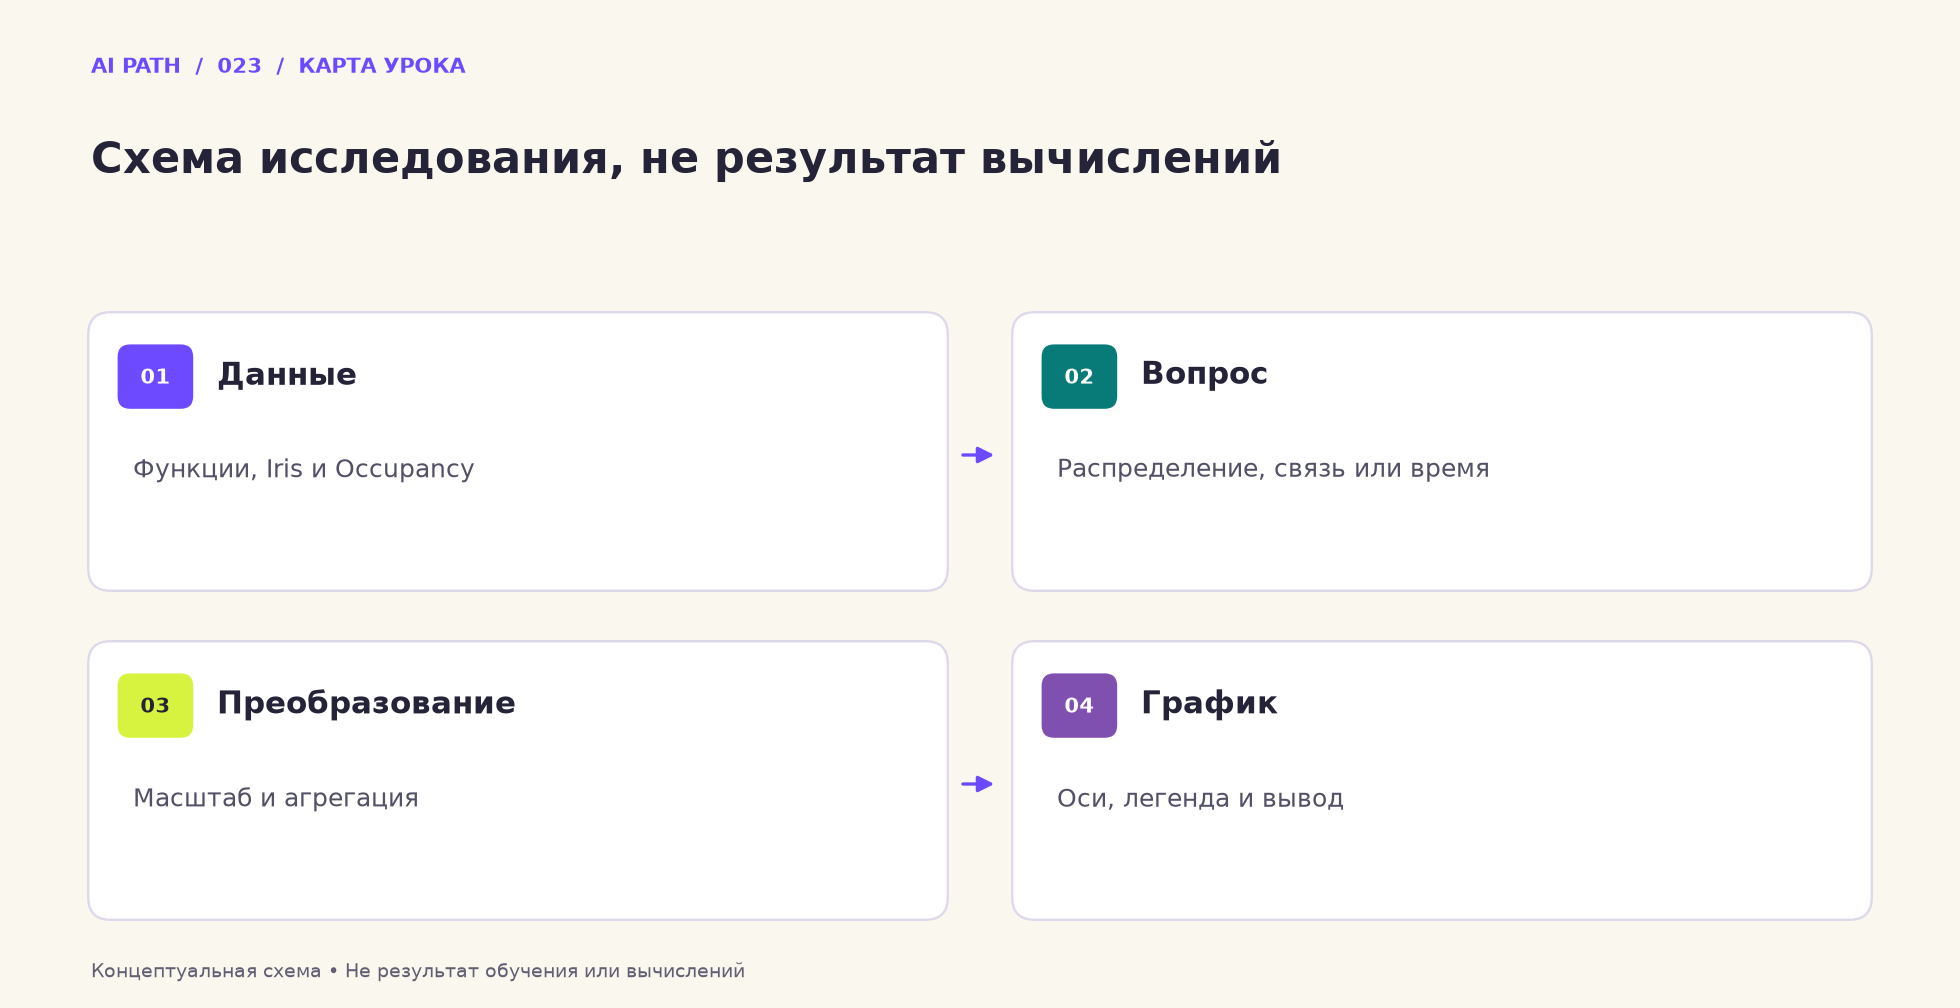

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Данные** — Функции, Iris и Occupancy
2. **Вопрос** — Распределение, связь или время
3. **Преобразование** — Масштаб и агрегация
4. **График** — Оси, легенда и вывод

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_Python_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Light
### *Часть 1: Matplotlib*

<a id="ai-023-section-01"></a>
## 01 · Функция и её оси

Сопоставьте значения x и y: передача только y в plot показывает индекс наблюдения по горизонтали.

_Далее — исходные ячейки учебного материала._

### **Задача 1**

Используя библиотеку Matplotlib, постройте график экспоненты. Подпишите оси. Дайте название графику.

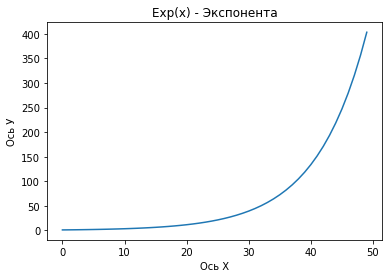

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np

y = np.exp(np.linspace(0,6,50)) #Генерируем последовательность и передаем в последовательность экспонеты

plt.xlabel('Ось X')
plt.ylabel('Ось У')
plt.title('Exp(x) - Экспонента')

plt.plot(y)
plt.show()

### **Задача 2**

Используя библиотеку Matplotlib, постройте графики функций $y = x^3$ и $y = x^2$ на одном графике. 

* Дайте название графику 
* Дайте названия осям
* Присвойте лейблы и выведите легенду
* Графики функций должны быть отрисованы пунктирными линиями (любыми из доступных на ваш вкус) 

In [ ]:
x = np.linspace(0, 10, 50) 
y1 = [i**2 for i in x]
y2 = [i**3 for i in x]

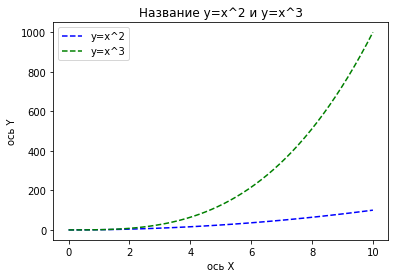

In [ ]:

#Графики функций должны быть отрисованы пунктирными линиями (любыми из доступных на ваш вкус)
plt.plot(x, y1, 'b--',label='y=x^2') # Визуализируем график для значения y1 (и задаем ему название (легенду))
plt.plot(x, y2, 'g--',label='y=x^3') # Визуализируем график для значения y2 (и задаем ему название (легенду))

plt.title('Название y=x^2 и y=x^3') # Задаем название графика
plt.xlabel('ось X') # ось х
plt.ylabel('ось Y') # ось y
plt.legend(loc='upper left') # Вызываем отображение легенды на графике
plt.show() # Фиксируем график

<a id="ai-023-section-02"></a>
## 02 · Изображение как массив

Посмотрите, как один массив выглядит с обычной и серой цветовой картой.

_Далее — исходные ячейки учебного материала._

### **Задача 3**

Выведите на экран картинку ascent, которая подгружается кодом ниже.

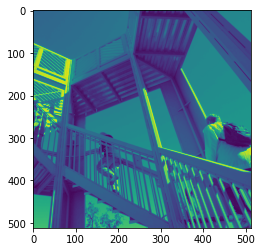

In [ ]:
from scipy import misc
img = misc.ascent()
plt.imshow(img)
plt.show()

### **Задача 4**

Выведите на экран картинку из третьей задачи, но в серых цветах (grayscale).

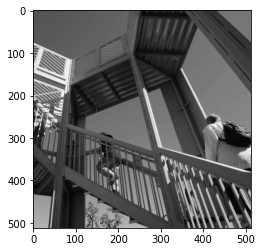

In [ ]:
plt.imshow(img, cmap='gray')
plt.show()

### *Часть 2: Seaborn*

<a id="ai-023-section-03"></a>
## 03 · Первое знакомство с Occupancy

Проверьте столбцы и временной индекс перед сравнением пар признаков.

_Далее — исходные ячейки учебного материала._

### **Задача 5**

Подгрузите данные datatraining.txt при помощи соответствующей функции библиотеки Pandas. Преобразуйте индекс в datetime index, удалите столбец с датой. Постройте график всех парных взаимосвязей с разметкой цвета в соответствии с метками классов (столбец Occupancy).

P.S. Используйте функцию sns.pairplot c параметром hue.

In [ ]:
#1.Подгрузите данные datatraining.txt при помощи соответствующей функции библиотеки Pandas
import pandas as pd 
df = pd.read_csv('/content/datatraining.txt') # загрузка файлов

In [ ]:
df

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.250000,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.000000,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.500000,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.250000,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.500000,0.004757,1
...,...,...,...,...,...,...,...
8139,2015-02-10 09:29:00,21.05,36.0975,433.0,787.250000,0.005579,1
8140,2015-02-10 09:29:59,21.05,35.9950,433.0,789.500000,0.005563,1
8141,2015-02-10 09:30:59,21.10,36.0950,433.0,798.500000,0.005596,1
8142,2015-02-10 09:32:00,21.10,36.2600,433.0,820.333333,0.005621,1


In [ ]:
#2. Преобразуйте индекс в datetime index, удалите столбец с датой
df.index = pd.to_datetime(df.date)
df.head() # Отображаем первые 5 строк датафрейма dataTraining
#Удаляем столбец date
df.drop('date', axis=1, inplace =True)
df.head()


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
date,,,,,,
2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


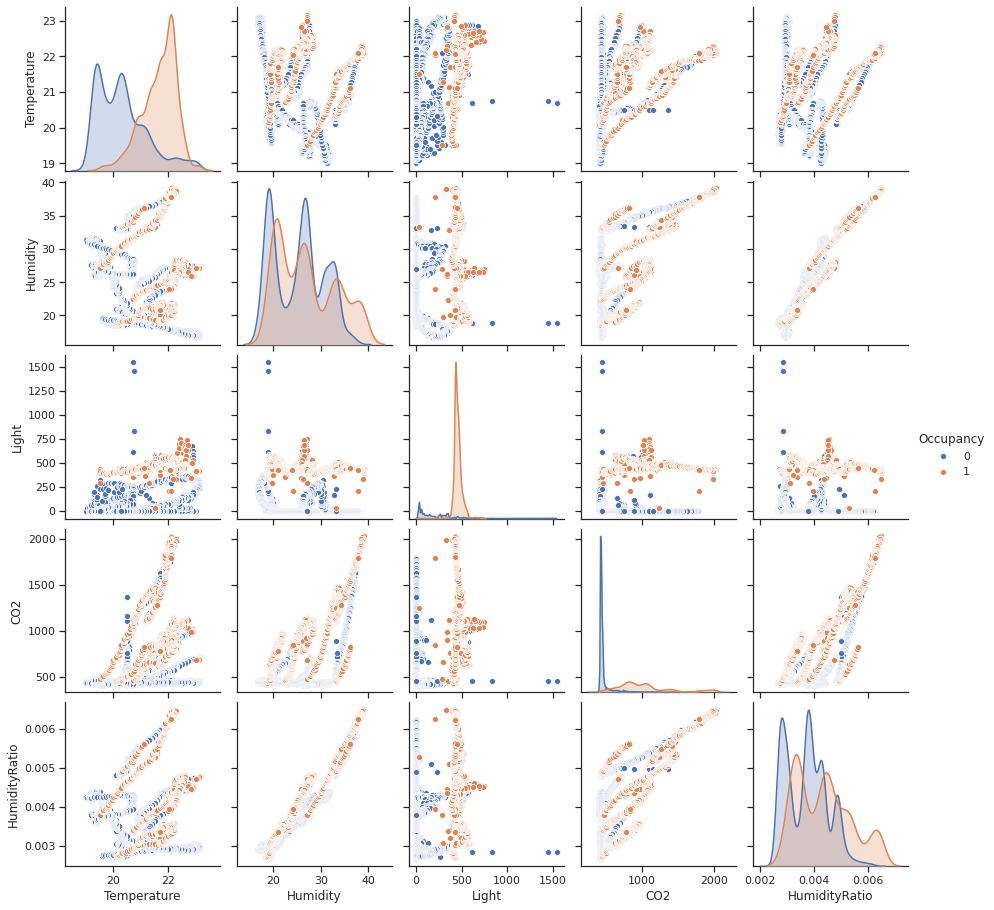

In [ ]:
#3. Постройте график всех парных взаимосвязей с разметкой цвета в соответствии с метками классов (столбец Occupancy).
import seaborn as sns;
sns.set(style="ticks", color_codes=True)
#P.S. Используйте функцию sns.pairplot c параметром hue.
sns.pairplot(df, hue='Occupancy')

<a id="ai-023-section-04"></a>
## 04 · Распределения и связи

Разделяйте стандартизацию, сравнение распределений и корреляцию: это разные вопросы к данным.

_Далее — исходные ячейки учебного материала._

### **Задача 6**

Постройте boxplot всех признаков.

P.S. График должен быть читаемым, т.е.
* отрегулируйте размер графика
* предварительно "отскейлите" все *числовые* признаки, т.е. приведите к стандартному нормальному распределению при помощи функции ниже

In [ ]:
# функция нормализации данных
def scale(df):
    return (df - df.mean()) / df.std()

In [ ]:
df_scale = scale(df) #нормализуем данные

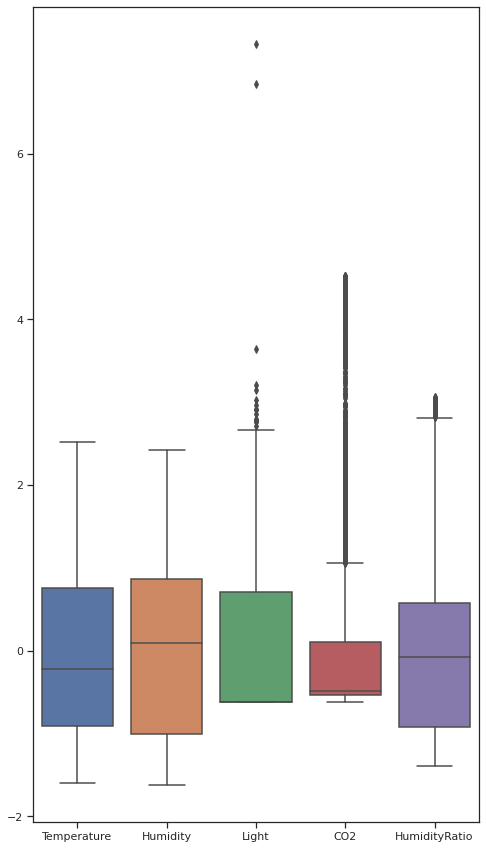

In [ ]:
plt.figure(figsize=(8, 15)) # задаем размер графика
sns.boxplot(data=df_scale.drop('Occupancy', axis=1))
plt.show()

### **Задача 7**

Постройте violinplot всех признаков.

P.S. Предварительно приведите их к стандартному нормальному распределению (как делали в предыдущей задаче).

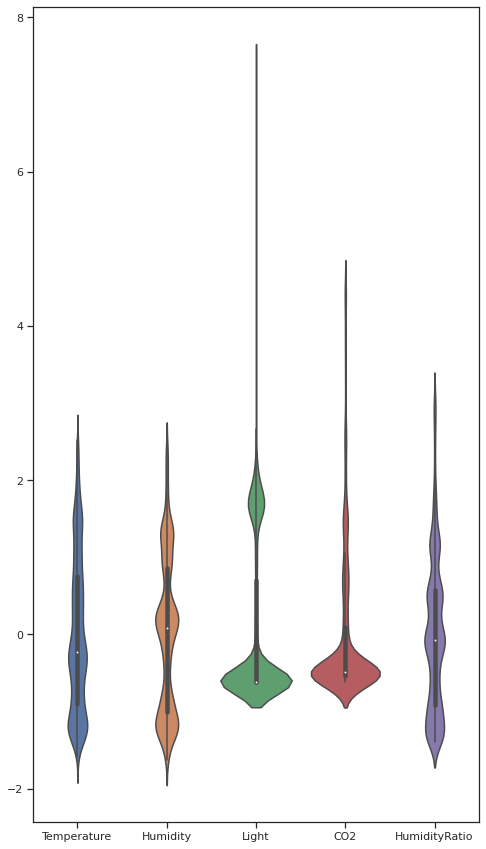

In [ ]:
plt.figure(figsize=(8, 15)) # задаем размер графика
sns.violinplot(data=df_scale.drop('Occupancy', axis=1))
plt.show()

### **Задача 8**

Нарисуйте heatmap матрицы корреляций, используя функцию sns.heatmap(). Отрегулируйте масштаб, установите произвольную палитру.

In [ ]:
corr = df_scale.drop('Occupancy', axis=1).corr() # находим попарную корреляцию данных

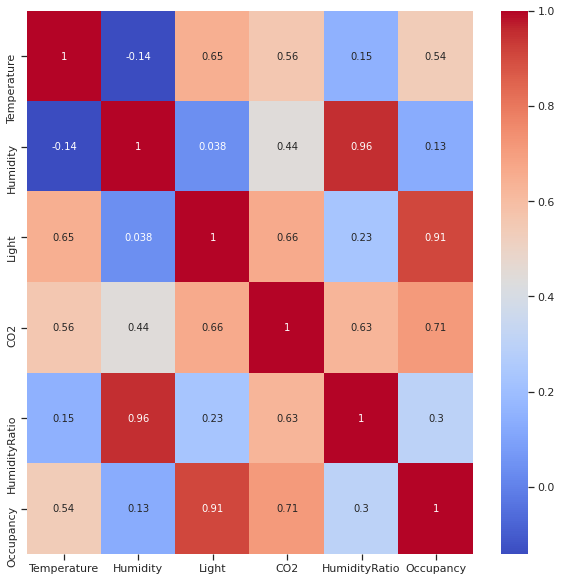

In [ ]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(),cmap='coolwarm',annot=True)



## Pro

### *Часть 1: Matplotlib*

<a id="ai-023-section-05"></a>
## 05 · Iris: признаки и классы

Сравните четыре признака на scatter-графиках, затем распределения и матрицу связей.

_Далее — исходные ячейки учебного материала._

### **Задача 1**

Используя библиотеку Matplotlib, для датасета "Ирисы", который подгружается кодом ниже, нарисуйте точечную диаграмму (scatter plot) всех четырех признаков. Каждый признак должен быть нарисован на отдельном графике. Используйте для этого subplot формата 2 на 2. Графики должны быть читаемыми, т.е. отрегулируйте размер subplot'ов. Добавьте названия признаков к каждому графику в качестве имени графика. Используйте метки классов (y) в качестве цветовой разметки. Добавьте расшифровку цветов, соответствующих меткам классов, в качестве лейблов.

P.S. Используйте функцию plt.scatter(x, y, color).

In [ ]:
from sklearn import datasets
data = datasets.load_iris(return_X_y=False)
X = data.data               
y = data.target             #цвет
names = data.target_names   #признаки

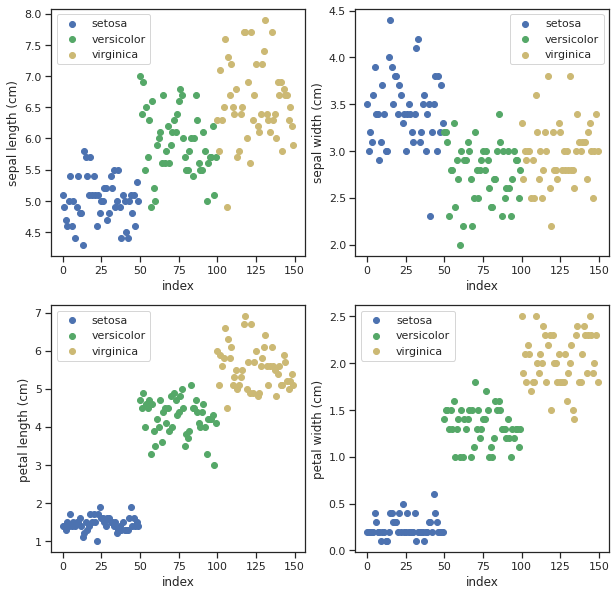

In [ ]:
plt.figure(1, figsize=(10,10))
for i in range(4): 
    l=1   
    plt.subplot(2,2,i+1)
    plt.scatter(range(50), X[:50, i], label=names[0], c='b')
    plt.scatter(range(50,100), X[50:100, i], label=names[1], c='g',)
    plt.scatter(range(100,150), X[100:150, i], label=names[2], c='y')
    plt.xlabel('index')
    plt.ylabel(data.feature_names[i])
    plt.legend()
    
plt.show()

### **Задача 2**

Используя библиотеку Matplotlib, постройте гистограмму для первого признака в датасете выше следующим образом:
* на одном графике должно быть три гистаграммы, по одной на каждый класс
* для этого используйте методологии подвыборки массива с условием
* количество бинов должно определяться автоматически (режим "auto")
* гистограмма должна быть читаемой, т.е. добавьте подписи, лейблы, названия и т.д.

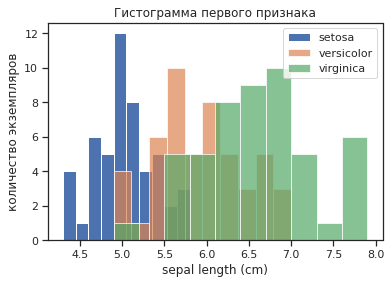

In [ ]:
feature = 0
plt.hist(X[y==0,feature])
plt.hist(X[y==1,feature], alpha=0.7)
plt.hist(X[y==2,feature], alpha=0.7)
plt.title('Гистограмма первого признака')
plt.xlabel(data.feature_names[0])
plt.ylabel('количество экземпляров')
plt.legend(names)
plt.show()

### **Задача 3**

Используя библиотеку Matplotlib, посчитайте матрицу корреляции между признаками и нарисуйте ее как heatmap. Подберите подходящую по смыслу цветовую гамму. Добавьте названия признаков в качестве тиков по осям. Добавьте отрисовку цветовой шкалы.

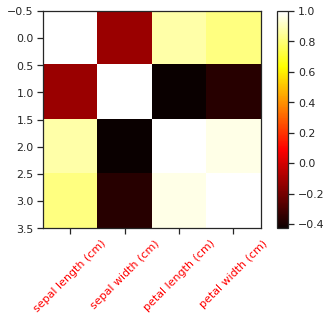

In [ ]:
iris = pd.DataFrame(X,y)
to_plot = iris.corr()
plt.imshow(to_plot, cmap='hot')
plt.colorbar() 
plt.xticks(range(4),data.feature_names, rotation=45, color='red')
plt.show()

### *Часть 2: Seaborn*

<a id="ai-023-section-06"></a>
## 06 · Время и агрегирование

Проверьте, что после пересчёта по 30 минутам признаки и метка относятся к одним временным интервалам.

_Далее — исходные ячейки учебного материала._

### **Задача 4**

Для датасета Occupancy (datatraining.txt) постройте диаграмму присутствия в разбивке по часам и меткам классов. Для этого сделайте следующее:
*   создайте новый столбец "hour", отвечающий соответствующему часу 
*   нарисуйте sns.countplot этого столбца в разбивке по Occupancy

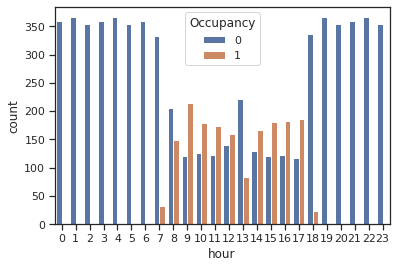

In [ ]:
df['hour'] = df.index.hour #создайте новый столбец "hour", отвечающий соответствующему часу
sns.countplot(data=df, x=df.hour, hue='Occupancy') #нарисуйте sns.countplot этого столбца в разбивке по Occupan
plt.show()

### **Задача 5**

Сделайте resample данных по получасовому интервалу с использованием усреднения для всех признаков. Обратите внимание, что столбец с метками класса Occupancy вместо усреднения нужно взять "как есть", т.е. resample c методом "asfreq" или "bfill".

Постройте sns.jointplot между признаками Light и CO2

In [ ]:
ssr1 = df.Occupancy.resample('30min').bfill() #с метками класса Occupancy вместо усреднения нужно взять "как есть", т.е. resample c методом "asfreq" или "bfill"
ssr2 = df.iloc[:,:-1].resample('30min').mean() # Сделайте resample данных по получасовому интервалу с использованием усреднения для всех признаков
res_ssr = pd.concat([ssr1,ssr2])

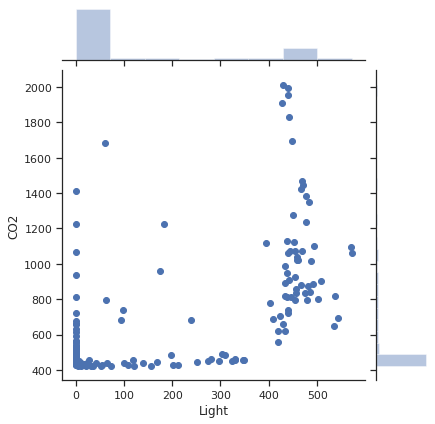

In [ ]:
sns.jointplot(x=res_ssr.Light,y=res_ssr.CO2, data = res_ssr)
plt.show()

### **Задача 6**

Постройте boxplot всех признаков с разбивкой по Occupancy. Для правильной отрисовки необходимо следующее:
*   создать новый текстовый столбец с расшифровкой столбца Occupancy, например, если 0 - то 'No', если 1 - то 'Yes
*   передать этот столбец в качестве соответствующего параметра боксплоту
*   для каждого признака нужен отдельный график

In [ ]:
df.insert(0,'StrOccupancy', df.Occupancy.values) 
df.replace({'StrOccupancy':{0:'No',1:'Yes'}})

,StrOccupancy,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,hour
date,,,,,,,,
2015-02-04 17:51:00,Yes,23.18,27.2720,426.0,721.250000,0.004793,1,17
2015-02-04 17:51:59,Yes,23.15,27.2675,429.5,714.000000,0.004783,1,17
2015-02-04 17:53:00,Yes,23.15,27.2450,426.0,713.500000,0.004779,1,17
2015-02-04 17:54:00,Yes,23.15,27.2000,426.0,708.250000,0.004772,1,17
2015-02-04 17:55:00,Yes,23.10,27.2000,426.0,704.500000,0.004757,1,17
...,...,...,...,...,...,...,...,...
2015-02-10 09:29:00,Yes,21.05,36.0975,433.0,787.250000,0.005579,1,9
2015-02-10 09:29:59,Yes,21.05,35.9950,433.0,789.500000,0.005563,1,9
2015-02-10 09:30:59,Yes,21.10,36.0950,433.0,798.500000,0.005596,1,9


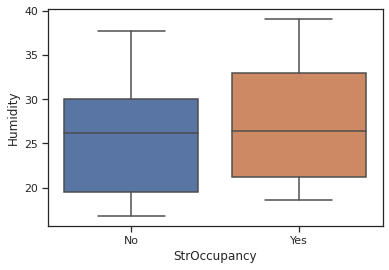

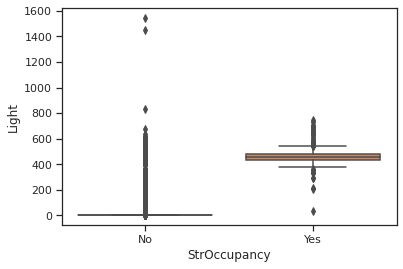

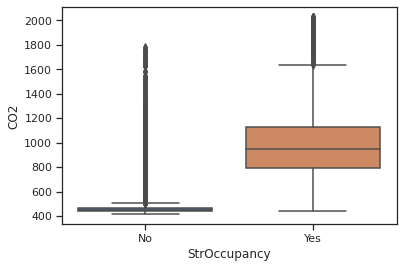

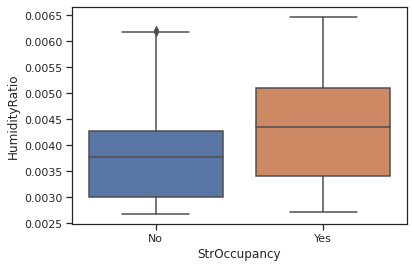

In [ ]:
for col in df.drop('Occupancy', axis=1).columns[2:-1]:
  sns.boxplot(x='StrOccupancy', y=col, data = df)
  plt.xticks([0, 1], ['No', 'Yes'])
  plt.show()

<a id="ai-023-practice"></a>
## Проверьте понимание

1. Чем отличаются plot(y) и plot(x, y) в ячейке 3?
2. Почему Occupancy стоит отдельно обсуждать в корреляционной матрице?
3. Проверьте форму и пропуски res_ssr после concat в ячейке 38.

### Один самостоятельный эксперимент

Для одного признака Occupancy сопоставьте boxplot и violinplot на одинаковой выборке.

**Критерий успеха:** Объяснены медиана, разброс и форма распределения; оси и группы подписаны.

<a id="ai-023-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Matplotlib/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90%D0%BF%D1%80%D0%B5%D0%BB%D1%8C%D1%81%D0%BA%D0%B8%D0%B9_%D0%BA%D1%83%D1%80%D1%81_2020_Light_Python_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_5.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Для Occupancy нужен внешний файл; его доступность здесь не подтверждалась.
- scipy.misc.ascent — устаревший путь загрузки изображения, зависящий от версии SciPy.
- В ячейке 38 concat по умолчанию объединяет строки; временное выравнивание требует отдельной проверки.
- В ячейке 31 не задан bins='auto', а replace в ячейке 41 не сохраняет результат. Код сохранён без исправлений.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.